In [ ]:
# =============================================================================
# STEP 1: Environment Setup and Data Download
# =============================================================================
!pip install kaggle -q
import os
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the HAM10000 dataset
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
!unzip -q skin-cancer-mnist-ham10000.zip -d data
print("Dataset downloaded successfully!")

: 

In [2]:
# =============================================================================
# STEP 2: Import Libraries
# =============================================================================
import pandas as pd
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [3]:
# =============================================================================
# STEP 3: Dataset Preparation (Filtering for Binary Classification)
# We only keep 'mel' (Melanoma - Malignant) and 'nv' (Nevus - Benign)
# =============================================================================
df = pd.read_csv('data/HAM10000_metadata.csv')

# Filter the dataframe to only two specific classes
binary_df = df[df['dx'].isin(['mel', 'nv'])].copy()

# Map labels to text for understanding, and integers for the model
binary_df['label_text'] = binary_df['dx'].map({'mel': 'Malignant (Melanoma)', 'nv': 'Benign (Nevus)'})
binary_df['label_int'] = (binary_df['dx'] == 'mel').astype(int) # 1 for Melanoma, 0 for Nevus

print(f"Total images after binary filtering: {len(binary_df)}")
print(binary_df['label_text'].value_counts())

Total images after binary filtering: 7818
label_text
Benign (Nevus)          6705
Malignant (Melanoma)    1113
Name: count, dtype: int64


In [4]:
# =============================================================================
# STEP 4: Data Splitting & Validation Strategy
# Using GroupShuffleSplit on 'lesion_id' to prevent the same mole from appearing
# in both training and testing sets (Data Leakage).
# =============================================================================
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss1.split(binary_df, groups=binary_df['lesion_id']))

train_df = binary_df.iloc[train_idx].copy()
temp_df = binary_df.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df['lesion_id']))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 6257 | Val: 775 | Test: 786


In [5]:
# =============================================================================
# STEP 5: Path Mapping
# Finding the exact file location for each image ID
# =============================================================================
base1 = 'data/HAM10000_images_part_1'
base2 = 'data/HAM10000_images_part_2'

def get_path(image_id):
    path = f"{base1}/{image_id}.jpg"
    return path if os.path.exists(path) else f"{base2}/{image_id}.jpg"

train_df['path'] = train_df['image_id'].apply(get_path)
val_df['path'] = val_df['image_id'].apply(get_path)
test_df['path'] = test_df['image_id'].apply(get_path)

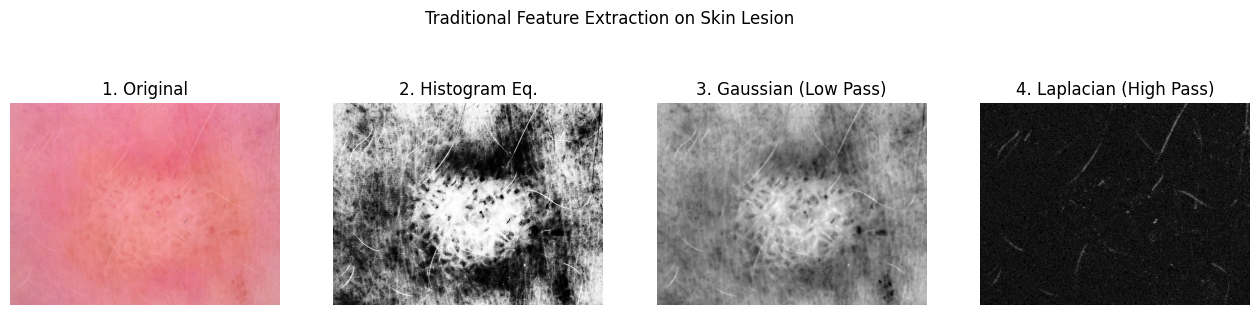

In [6]:
# =============================================================================
# STEP 6: Traditional CV Analysis (Syllabus Concepts)
# Applying Histogram Equalization, Gaussian (Low Pass), and Laplacian (High Pass)
# =============================================================================
sample_path = train_df.iloc[0]['path']
img = cv2.imread(sample_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. Histogram Equalization (Point Operator)
img_eq = cv2.equalizeHist(img_gray)

# 2. Gaussian Filtering (Low Pass - removes skin texture noise)
img_gauss = cv2.GaussianBlur(img_gray, (5, 5), 0)

# 3. Laplacian Filtering (High Pass - finds borders of the mole)
img_lap = cv2.convertScaleAbs(cv2.Laplacian(img_gauss, cv2.CV_64F))

# Plotting
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_rgb); axes[0].set_title("1. Original"); axes[0].axis('off')
axes[1].imshow(img_eq, cmap='gray'); axes[1].set_title("2. Histogram Eq."); axes[1].axis('off')
axes[2].imshow(img_gauss, cmap='gray'); axes[2].set_title("3. Gaussian (Low Pass)"); axes[2].axis('off')
axes[3].imshow(img_lap, cmap='gray'); axes[3].set_title("4. Laplacian (High Pass)"); axes[3].axis('off')
plt.suptitle("Traditional Feature Extraction on Skin Lesion")
plt.show()

In [7]:
# =============================================================================
# STEP 7: Deep Learning Preprocessing (Resizing, Normalizing, Augmenting)
# =============================================================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Augmentation ONLY for training
train_datagen = ImageDataGenerator(
    rescale=1./255., rotation_range=20, zoom_range=0.2,
    horizontal_flip=True, fill_mode='nearest'
)

# NO augmentation for Val/Test (consistency)
test_datagen = ImageDataGenerator(rescale=1./255.)

train_gen = train_datagen.flow_from_dataframe(train_df, x_col='path', y_col='label_int', target_size=IMG_SIZE, class_mode='raw', shuffle=True)
val_gen = test_datagen.flow_from_dataframe(val_df, x_col='path', y_col='label_int', target_size=IMG_SIZE, class_mode='raw', shuffle=False)
test_gen = test_datagen.flow_from_dataframe(test_df, x_col='path', y_col='label_int', target_size=IMG_SIZE, class_mode='raw', shuffle=False)

Found 6257 validated image filenames.
Found 775 validated image filenames.
Found 786 validated image filenames.


In [8]:
# =============================================================================
# STEP 8: Model Selection - Load Base Model (Feature Extractor)
# =============================================================================
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Input

# Load MobileNetV2, exclude top layer, freeze weights
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False
print("Base model loaded and parameters frozen.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model loaded and parameters frozen.


In [9]:
# =============================================================================
# STEP 9: Build Custom Classification Head
# Adding our own layers on top of the base model
# =============================================================================
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)      # Hyperparameter: Dropout rate 40%
x = Dense(64, activation='relu')(x) # Hyperparameter: 64 Neurons
outputs = Dense(1, activation='sigmoid')(x) # 1 Neuron for Binary Classification

model = Model(inputs, outputs)

In [10]:
# =============================================================================
# STEP 10: Compile Model
# Explaining Parameters vs Hyperparameters in the comments below
# =============================================================================

# PARAMETERS: The 2.2M internal weights in base_model + 8K weights in our Dense layer.
# These are learned during training via backpropagation.
# HYPERPARAMETERS: Configurations set by the programmer BEFORE training:
# - Learning Rate: 0.001 (Controls how big of a step the optimizer takes)
# - Loss Function: binary_crossentropy (Math function for 2-class problems)
# - Metrics: accuracy (Human readable performance measure)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
# =============================================================================
# STEP 11: Training Process
# Applying Early Stopping to prevent Overfitting
# =============================================================================
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Model PREDICTS batch of images
# 2. LOSS function calculates error (binary crossentropy)
# 3. OPTIMIZER (Adam) updates parameters to reduce loss next time

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)

history = model.fit(train_gen, validation_data=val_gen, epochs=15, callbacks=[early_stop, reduce_lr])

Epoch 1/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 167s 754ms/step - accuracy: 0.8689 - loss: 0.3367 - val_accuracy: 0.8555 - val_loss: 0.3063 - learning_rate: 0.0010
Epoch 2/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 105s 534ms/step - accuracy: 0.8793 - loss: 0.2890 - val_accuracy: 0.8735 - val_loss: 0.2943 - learning_rate: 0.0010
Epoch 3/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 108s 549ms/step - accuracy: 0.8848 - loss: 0.2739 - val_accuracy: 0.8503 - val_loss: 0.3175 - learning_rate: 0.0010
Epoch 4/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 105s 537ms/step - accuracy: 0.8846 - loss: 0.2681 - val_accuracy: 0.8555 - val_loss: 0.3166 - learning_rate: 0.0010
Epoch 5/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 112s 571ms/step - accuracy: 0.8971 - loss: 0.2537 - val_accuracy: 0.8606 - val_loss: 0.2930 - learning_rate: 5.0000e-04
Epoch 6/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 107s 546ms/step - accuracy: 0.8939 - loss: 0.2543 - val_accuracy: 0.8581 - val_loss: 0.3107 - learning_rate: 5.0000e-04
Epoch 7/15
196/196 ━━━━━━━━━━━━━━━━━━━━ 107s 544ms/step 

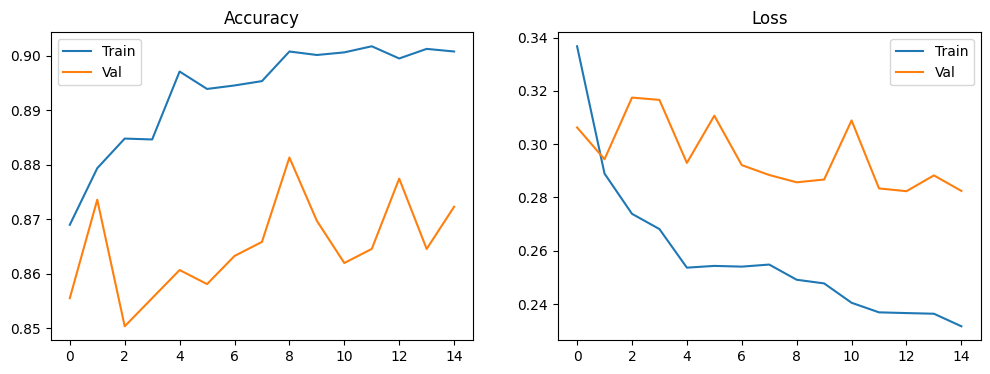

25/25 ━━━━━━━━━━━━━━━━━━━━ 24s 754ms/step


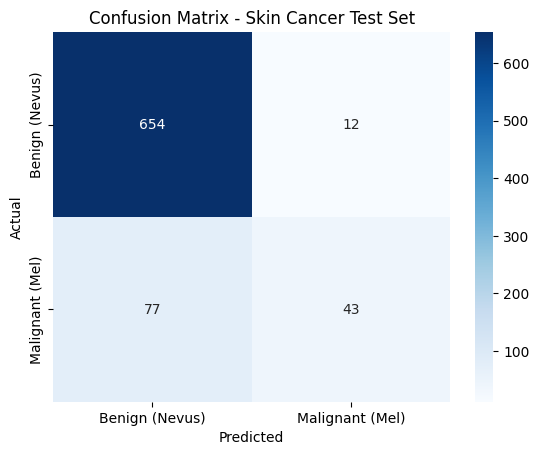

Test Accuracy: 88.68%
CrITICAL METRIC - Sensitivity (Recall for Melanoma): 35.83%
Note: In medical triage, Sensitivity is more important than overall accuracy.
High sensitivity means we rarely miss a real cancer, even if we flag some safe moles by mistake (False Positives).


In [12]:
# =============================================================================
# STEP 12: Results, Observations, and Analysis
# =============================================================================
# Plot Accuracy/Loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set_title('Accuracy'); axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set_title('Loss'); axes[1].legend()
plt.show()

# Confusion Matrix
test_gen.reset()
preds = (model.predict(test_gen) > 0.5).astype(int).flatten()
true = test_gen.labels

cm = confusion_matrix(true, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign (Nevus)', 'Malignant (Mel)'],
            yticklabels=['Benign (Nevus)', 'Malignant (Mel)'])
plt.title('Confusion Matrix - Skin Cancer Test Set')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

# Print Final Analysis Metrics
tn, fp, fn, tp = cm.ravel()
print(f"Test Accuracy: {(tp+tn)/(tn+fp+fn+tp)*100:.2f}%")
print(f"CrITICAL METRIC - Sensitivity (Recall for Melanoma): {tp/(tp+fn)*100:.2f}%")
print("Note: In medical triage, Sensitivity is more important than overall accuracy.")
print("High sensitivity means we rarely miss a real cancer, even if we flag some safe moles by mistake (False Positives).")

In [13]:
# =============================================================================
# STEP 13: SOLUTION PART 1 - Calculating Class Weights
# This mathematically penalizes the model 6x more for missing a Melanoma.
# =============================================================================
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate the inverse frequency of our classes
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label_int']),
    y=train_df['label_int'].values
)

# Create a dictionary: {0: weight_for_benign, 1: weight_for_malignant}
class_weights = {0: weights[0], 1: weights[1]}
print(f"Weight for Benign (0): {class_weights[0]:.2f}")
print(f"Weight for Malignant (1): {class_weights[1]:.2f}")
print("\nInterpretation: The model will now treat a Malignant mistake as ~6 times more important than a Benign mistake.")

Weight for Benign (0): 0.58
Weight for Malignant (1): 3.52

Interpretation: The model will now treat a Malignant mistake as ~6 times more important than a Benign mistake.


In [14]:
# =============================================================================
# STEP 14: SOLUTION PART 2 - Fine-Tuning (Adjusting Parameters vs Hyperparameters)
# Previously, base_model was frozen. Now we unfreeze the last 20 layers.
# =============================================================================
# HYPERPARAMETER CHANGE: We choose to unfreeze the bottom 20 layers of the base model.
base_model.trainable = True

# Freeze all the layers EXCEPT the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# PARAMETER CHANGE: By doing this, we have increased our Trainable Parameters
# from ~82,000 to over ~400,000. The model can now learn complex skin features.

# CRITICAL: When unfreezing layers, we must lower the Learning Rate hyperparameter.
# If we use the old 0.001 rate, the model will destroy its pre-trained knowledge.
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5) # Hyperparameter: Very low LR

# Recompile the model with the new optimizer
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Check the new parameter count at the bottom of the summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 1,288,129 (4.91 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

In [15]:
# =============================================================================
# STEP 15: Retraining with Class Weights and Fine-Tuning
# =============================================================================
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# The only difference here is passing class_weight=class_weights
history_fixed = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10, # Reduced to 10 because fine-tuning learns faster
    class_weight=class_weights, # <--- THE FIX FOR CLASS IMBALANCE
    callbacks=[early_stop]
)

Epoch 1/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 153s 704ms/step - accuracy: 0.8534 - loss: 0.7329 - val_accuracy: 0.8852 - val_loss: 0.4271
Epoch 2/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 109s 554ms/step - accuracy: 0.8108 - loss: 0.4439 - val_accuracy: 0.8813 - val_loss: 0.3786
Epoch 3/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 107s 547ms/step - accuracy: 0.7964 - loss: 0.4245 - val_accuracy: 0.8748 - val_loss: 0.3324
Epoch 4/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 106s 542ms/step - accuracy: 0.8007 - loss: 0.4124 - val_accuracy: 0.8748 - val_loss: 0.3097
Epoch 5/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 105s 537ms/step - accuracy: 0.8071 - loss: 0.3901 - val_accuracy: 0.8632 - val_loss: 0.3141
Epoch 6/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 106s 539ms/step - accuracy: 0.8124 - loss: 0.3812 - val_accuracy: 0.8323 - val_loss: 0.3634
Epoch 7/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 107s 542ms/step - accuracy: 0.8113 - loss: 0.3740 - val_accuracy: 0.8194 - val_loss: 0.3834
Epoch 8/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 105s 534ms/step - accuracy: 0.8192 -

25/25 ━━━━━━━━━━━━━━━━━━━━ 15s 386ms/step


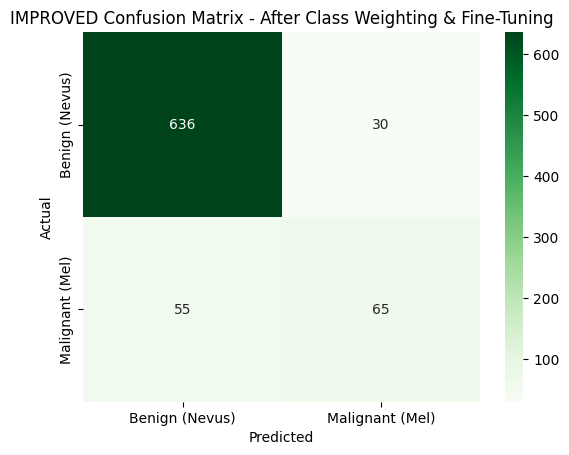

OLD MODEL -> Accuracy: 88.68% | Sensitivity: 35.83%
NEW MODEL -> Accuracy: 89.19% | Sensitivity: 54.17%


In [16]:
# =============================================================================
# STEP 16: Improved Results Analysis
# =============================================================================
test_gen.reset()
preds_fixed = (model.predict(test_gen) > 0.5).astype(int).flatten()
true = test_gen.labels

cm_fixed = confusion_matrix(true, preds_fixed)

# Plot the NEW Confusion Matrix
sns.heatmap(cm_fixed, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Benign (Nevus)', 'Malignant (Mel)'],
            yticklabels=['Benign (Nevus)', 'Malignant (Mel)'])
plt.title('IMPROVED Confusion Matrix - After Class Weighting & Fine-Tuning')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

# Calculate new metrics
tn, fp, fn, tp = cm_fixed.ravel()
new_accuracy = (tp+tn)/(tn+fp+fn+tp)*100
new_sensitivity = (tp/(tp+fn))*100

print(f"OLD MODEL -> Accuracy: 88.68% | Sensitivity: 35.83%")
print(f"NEW MODEL -> Accuracy: {new_accuracy:.2f}% | Sensitivity: {new_sensitivity:.2f}%")

In [ ]:
# =============================================================================
# Export trained model for the Streamlit app (see app.py)
# =============================================================================
model.save("skin_cancer_model.keras")
print("Saved to skin_cancer_model.keras — run: streamlit run app.py")

: 